# 01 · Carga y EDA
    **Objetivo.** Conocer la nube de la fábrica antes de elegir grupos. Vamos a revisar
    coordenadas, color y normales, y guardar una muestra voxel reproducible.
    Antes de mirar: ¿dónde habrá más puntos, en el piso o en las partes altas?

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Primero, revisamos qué llegó
Las coordenadas ubican cada punto; el color describe su apariencia y las normales su orientación. No tenemos etiquetas reales.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
assert len(cloud['xyz']) == 1647021
assert all(np.isfinite(v).all() for v in cloud.values())
columns = ['x','y','z','r','g','b','nx','ny','nz']
values = np.column_stack([cloud['xyz'], cloud['rgb'], cloud['normals']])
stats = pd.DataFrame(values, columns=columns).describe().T
stats.to_csv(CACHE / 'clase_eda_estadisticas.csv')
display(stats)
print('Normales con norma cero:', int((np.linalg.norm(cloud['normals'], axis=1) == 0).sum()))

,count,mean,std,min,25%,50%,75%,max
x,1647021.0,10.911407,7.302562,-2.582234,4.675776,10.371089,16.748074,28.803471
y,1647021.0,4.695280,8.535370,-11.873617,-2.094372,4.806885,11.139641,22.994278
z,1647021.0,2.367259,3.918335,-2.311177,-1.447278,1.354237,5.669920,14.459072
r,1647021.0,114.777435,64.364578,0.000000,62.000000,101.000000,149.000000,255.000000
g,1647021.0,112.606255,69.750458,0.000000,51.000000,101.000000,155.000000,255.000000
b,1647021.0,109.951340,68.527878,0.000000,49.000000,96.000000,152.000000,255.000000
nx,1647021.0,0.010551,0.485318,-0.999999,-0.042270,0.000983,0.067579,0.999999
ny,1647021.0,-0.030796,0.445691,-0.999999,-0.081212,-0.002944,0.057137,0.999999
nz,1647021.0,0.123111,0.741356,-0.999999,-0.481712,0.008397,0.997711,0.999999


Normales con norma cero: 2


### Miremos las distribuciones
Un histograma cuenta puntos por intervalo. Para el color superponemos los tres canales originales, todavía sin convertir a Lab.

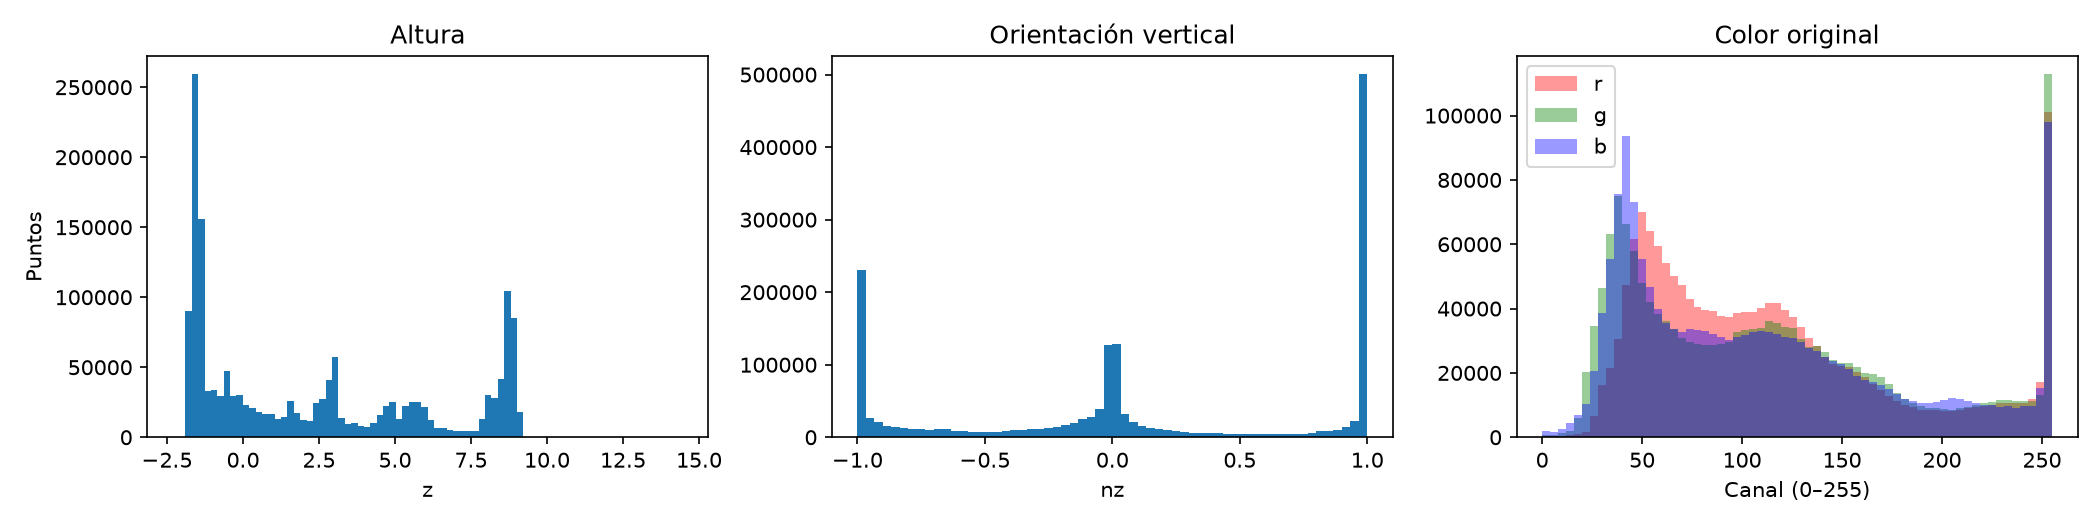

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(cloud['xyz'][:,2], bins=80); ax[0].set(xlabel='z', ylabel='Puntos', title='Altura')
ax[1].hist(cloud['normals'][:,2], bins=60); ax[1].set(xlabel='nz', title='Orientación vertical')
for j, color in enumerate(['r','g','b']):
    ax[2].hist(cloud['rgb'][:,j], bins=64, alpha=.4, color=color, label=color)
ax[2].set(xlabel='Canal (0–255)', title='Color original'); ax[2].legend()
fig.tight_layout(); fig.savefig(FIG / '01_histogramas.png', dpi=150); display(Image(filename=str(FIG / '01_histogramas.png'))); plt.close(fig)

### Elegimos el tamaño del voxel con los datos
Cada voxel conserva su primer punto, sin promediar colores ni normales. Empezamos en 0.12 unidades y ajustamos hasta tener entre 60 mil y 150 mil representantes; apuntamos a 90 mil. El algoritmo no es aleatorio. Guardamos índices, tamaño de voxel e IDs para poder auditar y repetir.

In [5]:
voxel = .12
trials = []
for attempt in range(12):
    sample_idx = voxel_downsample(cloud['xyz'], voxel)
    trials.append({'voxel': voxel, 'n': len(sample_idx)})
    if 60000 <= len(sample_idx) <= 150000:
        break
    voxel *= np.clip((len(sample_idx) / 90000)**.5, .65, 1.7)
assert 60000 <= len(sample_idx) <= 150000
ids = voxel_ids(cloud['xyz'], voxel)
assert np.array_equal(ids[sample_idx], np.arange(len(sample_idx)))
if (OUT/'sample_idx.npy').exists():
    assert np.array_equal(sample_idx,np.load(OUT/'sample_idx.npy')), 'La muestra común cambió'
np.save(OUT / 'sample_idx.npy', sample_idx)
np.save(CACHE / 'clase_voxel_ids.npy', ids.astype(np.int32))
(CACHE / 'clase_muestra.json').write_text(json.dumps({'voxel': voxel, 'n': len(sample_idx),
    'n_original': len(cloud['xyz']), 'seed': 0, 'trials': trials}, indent=2))
display(pd.DataFrame(trials))

,voxel,n
0,0.120000,218385
1,0.186927,93903


### La nube con sus colores originales
Dibujamos hasta 40 mil puntos de la nube original para que la figura sea legible. Esto solo reduce el dibujo; la muestra de trabajo sigue siendo la guardada arriba.

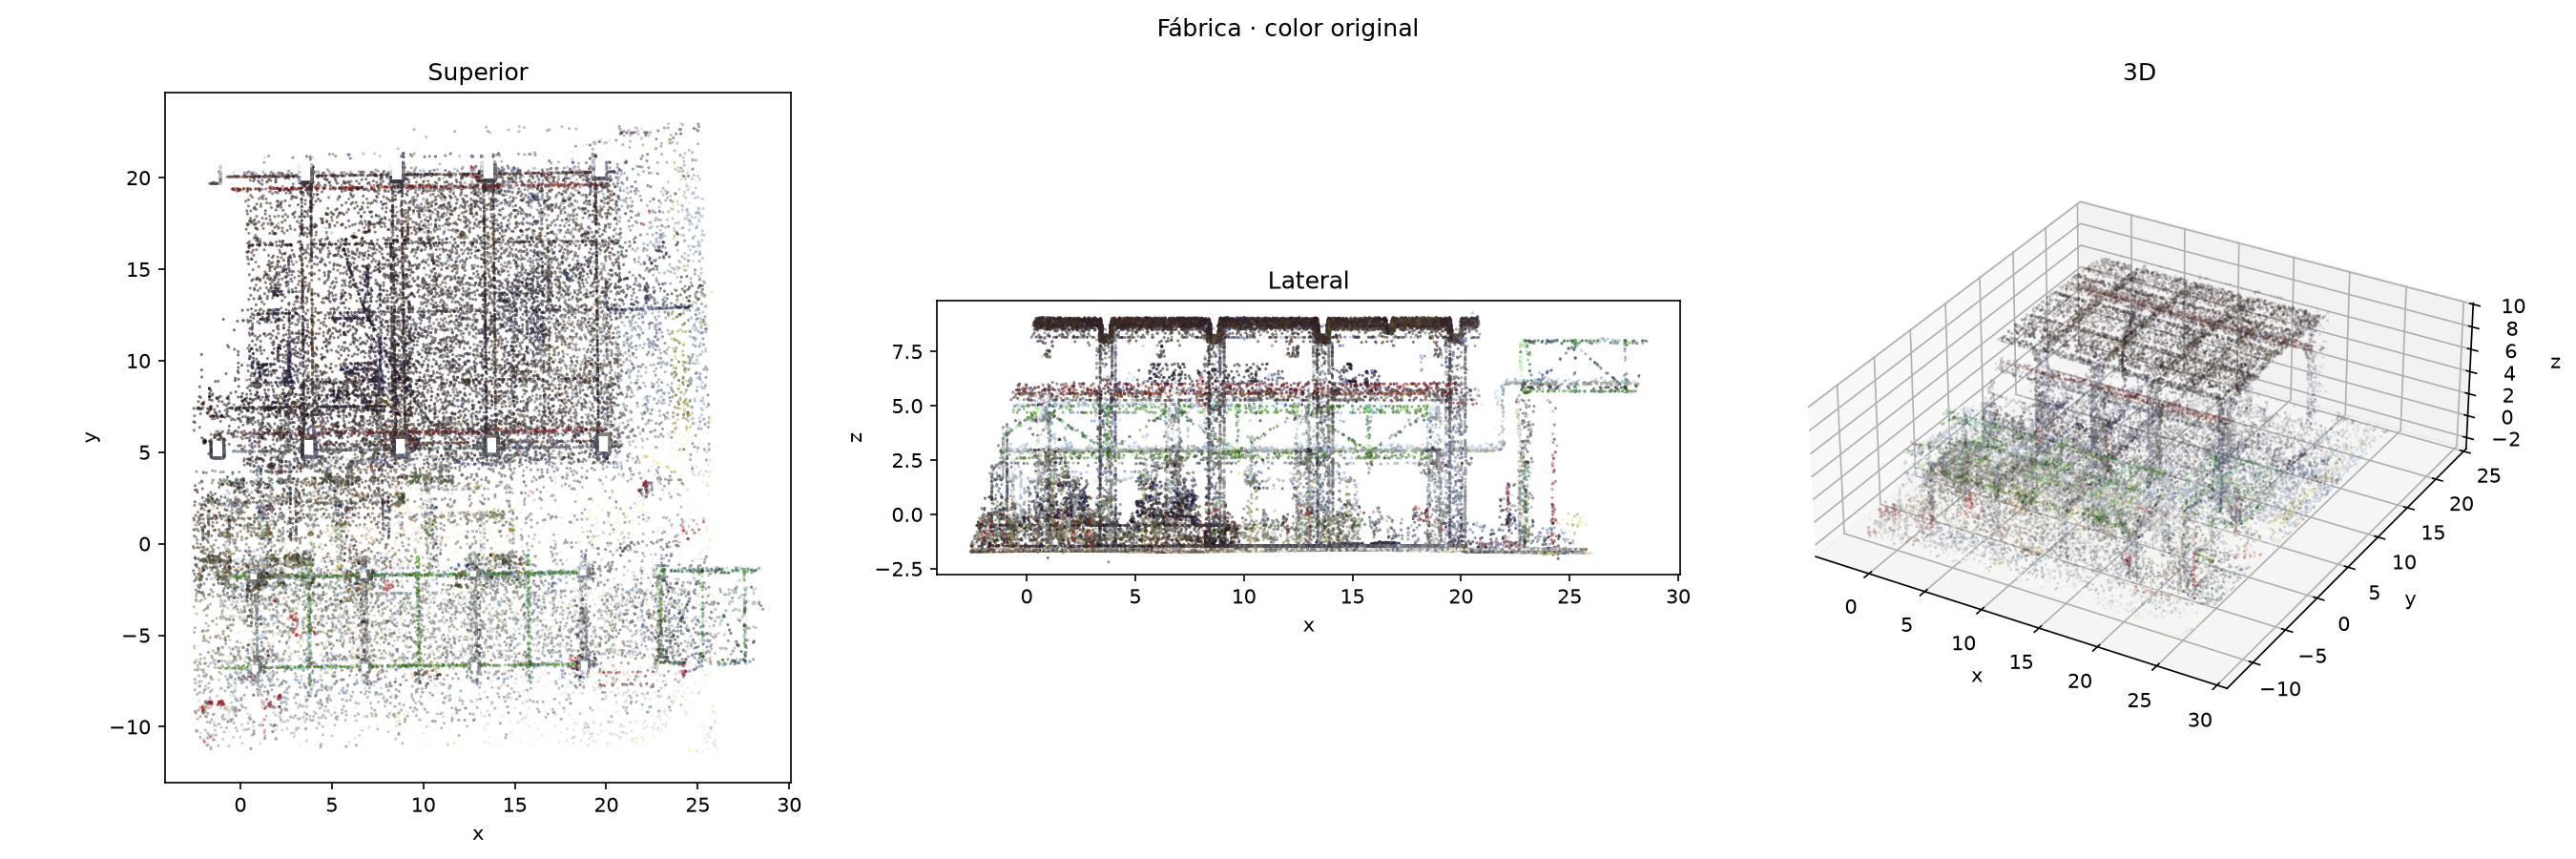

{'n_original': 1647021, 'n_sample': 93903, 'voxel': np.float64(0.18692672361115195), 'z_min': -2.3111774921417236, 'z_max': 14.45907211303711, 'segundos_notebook': 6.195417427999928}


In [6]:
path = FIG / '01_original.png'
scatter_views(cloud['xyz'], cloud['rgb'], path, 'Fábrica · color original', max_points=40000, seed=0)
display(Image(filename=str(path)))
payload = dict(n_original=len(cloud['xyz']), n_sample=len(sample_idx), voxel=voxel,
    z_min=float(cloud['xyz'][:,2].min()), z_max=float(cloud['xyz'][:,2].max()),
    segundos_notebook=time.perf_counter()-START)
(CACHE / 'clase_resumen_01.json').write_text(json.dumps(payload, indent=2))
print(payload)

## Qué aprendimos / qué falló

Con 1,647,021 puntos, z va de -2.311 a 14.459. El voxel 0.18693 dejó 93,903 representantes, dentro del rango pedido. Conservamos puntos reales y sus normales, pero la muestra da un peso más parejo al espacio que a la densidad original. Los histogramas describen distribuciones, no clases; todavía no sabemos cuáles son objetos físicos.